In [1]:
import trenchripper as tr

import dask.dataframe as dd

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [ ]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="2:00:00",
#     local=False,
#     n_workers=100,#200,#20,
#     n_workers_min=20,#200,
#     memory="8GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()
# dask_controller.displaydashboard()

110m
2:00:00


In [2]:
import pickle as pkl

def pivot_df(df, index_name = 'opLAG1_id'):
    df_ = (
        df
        .reset_index()
        .pivot(index=index_name,
               columns=['Estimator', 'Variable(s)'],
               values = 'Value')
        .reset_index()
        .pipe(lambda df: df.rename(columns=lambda x: '_'.join(x) if isinstance(x, tuple) else x))
            # Make column index a single level
    )

    df_.columns = ['_'.join(col).strip() for col in df_.columns.values]
    df_ = (df_
         .rename(columns={index_name + '_': index_name})
    )

    return df_
    
def open_and_format_average_results(filename_timepoints: str,
                                    filename_growth: str,
                                    filename_cell_cycle: str,
                                    filename_gRNA: str,
                                    cols_gRNA: list,
                                    lib_index = 'opLAG1_id'):

    with open(filename_timepoints, 'rb') as f:
        df_timepoints = pkl.load(f)

    with open(filename_growth, 'rb') as f:
        df_growth = pkl.load(f)

    with open(filename_cell_cycle, 'rb') as f:
        df_cycle = pkl.load(f)

    with (open(filename_gRNA, 'rb', )) as f:
        df_lib = (
            pkl.load(f)
            .loc[:, cols_gRNA]
            .reset_index()
            .reset_index()
            .rename(columns={'level_0': lib_index})
        )

    # Generate the gRNA df
    df_gRNAs = (df_timepoints
                .reset_index()
                .loc[:, [lib_index, 'sgRNA', 'locus_tag', 'Gene', 'Predicted_Efficacy', 'Category', 'TargetID', 'N Observations']]
                .drop_duplicates(subset=lib_index)
                .merge(df_lib.loc[:,[lib_index, 'query_spacer', 'relative_fitness_mean']], on=lib_index, how='left')
    )

    # Pivot the dfs
    pdf_timepoints = pivot_df(df_timepoints, index_name=lib_index)
    pdf_growth = pivot_df(df_growth, index_name=lib_index)
    pdf_cycle = pivot_df(df_cycle, index_name=lib_index)

    # Merge everything
    df_ = pdf_timepoints.merge(pdf_growth, on=lib_index).merge(pdf_cycle, on=lib_index).merge(df_gRNAs, on=lib_index)

    return df_

In [3]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

headpath = '/home/lag36/scratch/lag36/'

In [4]:
dir_run_1 = headpath + '2024-08-16_lLAG8_Run-1/Growth_Division/'
run_1_dd_prefix = '2024-08-16_lLAG8_Steady_State_'

filename_timepoints = dir_run_1 + run_1_dd_prefix + 'Timepoints_df_Estimators.pkl'
filename_growth = dir_run_1 + run_1_dd_prefix + 'Growth_df_Estimators.pkl'
filename_cell_cycle = dir_run_1 + run_1_dd_prefix + 'Cell_Cycle_df_Estimators.pkl'

filename_gRNA = '/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/df_ess_to_order_all.pkl'

cols_gRNA = ['locus_tag', 'gene', 'offset', 'position_offset', 'query_spacer', 'gene_category',
       'relative_fitness_mean', 'relative_fitness_std', 'category']
lib_index = 'opLAG1_id'

df_run_1_pip_1 = open_and_format_average_results(filename_timepoints, filename_growth, filename_cell_cycle, filename_gRNA, cols_gRNA, lib_index)

usecols = ['opLAG1_id',
           'Mean (Robust)_mCherry mean_intensity', 
           'Mean (Robust)_major_axis_length',
           'Mean (Robust)_minor_axis_length',
           'Mean (Robust)_Instantaneous Growth Rate: Volume',
           'Mean (Robust)_Delta time (s)',
           'Mean (Robust)_Septum Displacement Length Normalized',
           'Gene',
           'Category',
           'N Observations']

df_run_1_pip_1 = df_run_1_pip_1.loc[:, usecols]
df_run_1_pip_1.columns = df_run_1_pip_1.columns.str.replace('Mean (Robust)_', '')

dict_col_rename = {'major_axis_length': 'Length',
                   'minor_axis_length': 'Width'}

df_run_1_pip_1 = df_run_1_pip_1.rename(columns=dict_col_rename)

In [5]:
dir_run_1 = headpath + '2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/Growth_Division/'
run_1_dd_prefix = '2025-05-14_lLAG8_MBM_37C_Run-01_PipRun-02_Steady_State_'

filename_timepoints = dir_run_1 + run_1_dd_prefix + 'Timepoints_df_Estimators.pkl'
filename_growth = dir_run_1 + run_1_dd_prefix + 'Growth_df_Estimators.pkl'
filename_cell_cycle = dir_run_1 + run_1_dd_prefix + 'Cell_Cycle_df_Estimators.pkl'

filename_gRNA = '/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/df_ess_to_order_all.pkl'

cols_gRNA = ['locus_tag', 'gene', 'offset', 'position_offset', 'query_spacer', 'gene_category',
       'relative_fitness_mean', 'relative_fitness_std', 'category']
lib_index = 'opLAG1_id'

df_run_1_pip_2 = open_and_format_average_results(filename_timepoints, filename_growth, filename_cell_cycle, filename_gRNA, cols_gRNA, lib_index)

usecols = ['opLAG1_id',
           'Mean (Robust)_mCherry mean_intensity', 
           'Mean (Robust)_Length',
           'Mean (Robust)_Width',
           'Mean (Robust)_Instantaneous Growth Rate: Volume',
           'Mean (Robust)_Delta time (s)',
           'Mean (Robust)_Septum Displacement Length Normalized',
           'Gene',
           'Category',
           'N Observations']

df_run_1_pip_2 = df_run_1_pip_2.loc[:, usecols]
df_run_1_pip_2.columns = df_run_1_pip_2.columns.str.replace('Mean (Robust)_', '')

In [6]:
dir_run_9 = headpath + '2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Growth_Division/'
run_9_dd_prefix = '2025-03-26_lLAG8_MBM_37_Run9_Steady_State_'

filename_timepoints = dir_run_9 + run_9_dd_prefix + 'Timepoints_df_Estimators.pkl'
filename_growth = dir_run_9 + run_9_dd_prefix + 'Growth_df_Estimators.pkl'
filename_cell_cycle = dir_run_9 + run_9_dd_prefix + 'Cell_Cycle_df_Estimators.pkl'

filename_gRNA = '/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/df_ess_to_order_all.pkl'

cols_gRNA = ['locus_tag', 'gene', 'offset', 'position_offset', 'query_spacer', 'gene_category',
       'relative_fitness_mean', 'relative_fitness_std', 'category']
lib_index = 'opLAG1_id'

df_run_9 = open_and_format_average_results(filename_timepoints, filename_growth, filename_cell_cycle, filename_gRNA, cols_gRNA, lib_index)

df_run_9 = df_run_9.loc[:, usecols]
df_run_9.columns = df_run_9.columns.str.replace('Mean (Robust)_', '')

In [7]:
def get_comparison_df(df_left, df_right, n_observations_min, suffix_left = '_left', suffix_right = '_right'):
    return df_left.loc[df_left['N Observations'] > n_observations_min].merge(
        df_right.loc[df_right['N Observations'] > n_observations_min],
        on='opLAG1_id',
        how='inner',
        suffixes=(suffix_left, suffix_right)
    )

In [8]:
n_observations_min = 20

df_merged = \
df_run_1_pip_1.loc[lambda df_: df_['N Observations'] > n_observations_min, :].merge(
    df_run_1_pip_2.loc[lambda df_: df_['N Observations'] > n_observations_min, :],
    on = 'opLAG1_id',
    how = 'inner',
    suffixes=('_run_1_pip1', '_run_1_pip2')
).merge(
    df_run_9.loc[lambda df_: df_['N Observations'] > n_observations_min, :],
    on = 'opLAG1_id',
    how = 'inner',
    suffixes=('', '_run_9')
)
# df_run_9.loc[lambda df_: df_['N Observations'] > n_observations_min, :]

<Axes: xlabel='Instantaneous Growth Rate: Volume', ylabel='Length'>

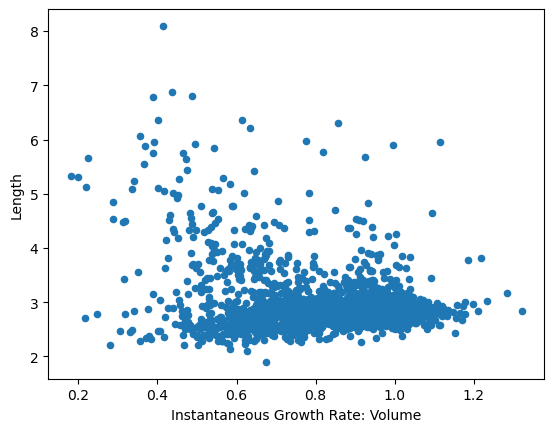

In [12]:
df_run_1_pip_1.plot(
    x = 'Instantaneous Growth Rate: Volume',
    y = 'Length',
    kind = 'scatter'
)

<Axes: xlabel='Instantaneous Growth Rate: Volume', ylabel='Length'>

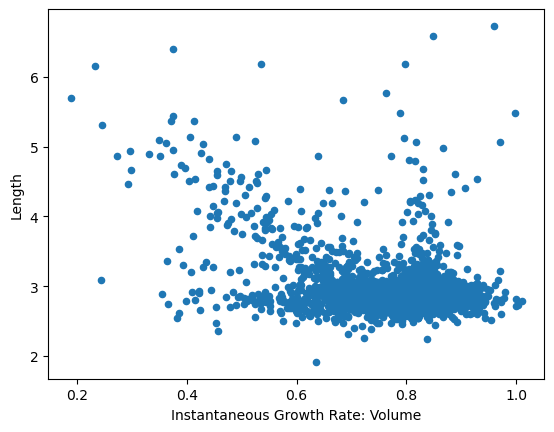

In [14]:
df_run_9.plot(
    x = 'Instantaneous Growth Rate: Volume',
    y = 'Length',
    kind = 'scatter'
)

<Axes: xlabel='Instantaneous Growth Rate: Volume', ylabel='Length'>

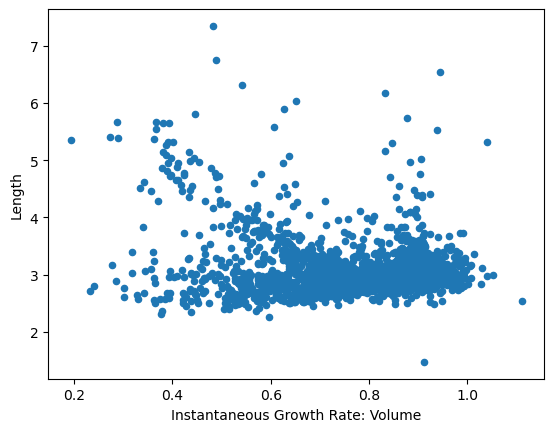

In [13]:
df_run_1_pip_2.plot(
    x = 'Instantaneous Growth Rate: Volume',
    y = 'Length',
    kind = 'scatter'
)

In [148]:
df_merged.columns

Index(['opLAG1_id', 'mCherry mean_intensity_run_1_pip1', 'Length_run_1_pip1',
       'Width_run_1_pip1', 'Instantaneous Growth Rate: Volume_run_1_pip1',
       'Delta time (s)_run_1_pip1',
       'Septum Displacement Length Normalized_run_1_pip1', 'Gene_run_1_pip1',
       'Category_run_1_pip1', 'N Observations_run_1_pip1',
       'mCherry mean_intensity_run_1_pip2', 'Length_run_1_pip2',
       'Width_run_1_pip2', 'Instantaneous Growth Rate: Volume_run_1_pip2',
       'Delta time (s)_run_1_pip2',
       'Septum Displacement Length Normalized_run_1_pip2', 'Gene_run_1_pip2',
       'Category_run_1_pip2', 'N Observations_run_1_pip2',
       'mCherry mean_intensity', 'Length', 'Width',
       'Instantaneous Growth Rate: Volume', 'Delta time (s)',
       'Septum Displacement Length Normalized', 'Gene', 'Category',
       'N Observations'],
      dtype='object')

Intercept: -0.20595978474616405
Coefficient: 1.134072847448146
R^2: 0.8757710233847693


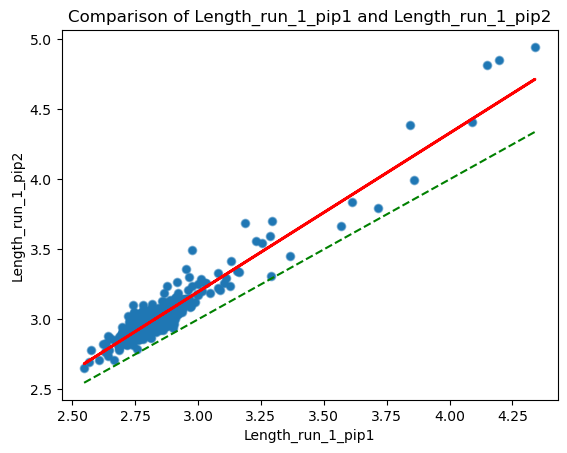

In [139]:
variable = 'Length'

x_name = variable + '_run_1_pip1'
y_name = variable + '_run_1_pip2'

df_merged.plot(
    x=x_name,
    y=y_name,
    kind='scatter',
    title=f'Comparison of {x_name} and {y_name}',
)

# # Make a linear fit
# import numpy as np
# import matplotlib.pyplot as plt

x = df_merged[x_name].values.reshape(-1, 1)
y = df_merged[y_name].values.reshape(-1, 1)

model = LinearRegression()

model.fit(x, y)
y_pred = model.predict(x)

plt.scatter(x, y, alpha=0.5)
plt.plot(x, y_pred, color='red', linewidth=2)

print(f"Intercept: {model.intercept_[0]}")
print(f"Coefficient: {model.coef_[0][0]}")
print(f"R^2: {model.score(x, y)}")

# Plot an identity line
x_vals = np.linspace(np.min(x), np.max(x), 2)
y_vals = x_vals
plt.plot(x_vals, y_vals, color='green', linestyle='--', label='Identity line')

In [163]:
# Write a function that makes the figure above on an ax object passed as an argument
def compare_variables(
    df_merged,
    x_name,
    y_name,
    ax
):
    
    df_merged.plot(
    x=x_name,
    y=y_name,
    kind='scatter',
    title=f'Comparison of {x_name}\n and {y_name}',
    ax=ax,
)
    
    x = df_merged[x_name].values.reshape(-1, 1)
    y = df_merged[y_name].values.reshape(-1, 1)

    model = LinearRegression()

    model.fit(x, y)
    y_pred = model.predict(x)

    ax.scatter(x, y, alpha=0.5)
    ax.plot(x, y_pred, color='red', linewidth=2)

#     print(f"Intercept: {model.intercept_[0]}")
#     print(f"Coefficient: {model.coef_[0][0]}")
#     print(f"R^2: {model.score(x, y)}")

    # Insert Intercept, coefficient, and r^2 in the plot
    ax.text(0.05, 0.95, f'Intercept: {model.intercept_[0]:.2f}', transform=ax.transAxes, fontsize=12,
            verticalalignment='top')
    ax.text(0.05, 0.90, f'Coefficient: {model.coef_[0][0]:.2f}', transform=ax.transAxes, fontsize=12,
            verticalalignment='top')
    ax.text(0.05, 0.85, f'R^2: {model.score(x, y):.2f}', transform=ax.transAxes, fontsize=12,
            verticalalignment='top')
    
    # Plot an identity line
    x_vals = np.linspace(np.min(x), np.max(x), 2)
    y_vals = x_vals
    ax.plot(x_vals, y_vals, color='green', linestyle='--', label='Identity line')

In [166]:
df_merged

,opLAG1_id,mCherry mean_intensity_run_1_pip1,Length_run_1_pip1,Width_run_1_pip1,Instantaneous Growth Rate: Volume_run_1_pip1,Delta time (s)_run_1_pip1,Septum Displacement Length Normalized_run_1_pip1,Gene_run_1_pip1,Category_run_1_pip1,N Observations_run_1_pip1,...,N Observations_run_1_pip2,mCherry mean_intensity,Length,Width,Instantaneous Growth Rate: Volume,Delta time (s),Septum Displacement Length Normalized,Gene,Category,N Observations
0,4,1086.016016,2.873803,1.319822,0.964598,2640.047005,0.029129,dnaA,essential,27,...,60.0,794.311384,2.885868,1.234657,0.834232,2895.340365,0.026377,dnaA,essential,31.0
1,6,1073.494900,2.780821,1.327457,0.980001,2640.284431,0.030990,dnaA,essential,39,...,94.0,785.560935,2.849681,1.230937,0.851678,2733.804275,0.027374,dnaA,essential,42.0
2,7,1085.596676,2.832659,1.322688,0.957271,2480.044740,0.030325,dnaA,essential,30,...,80.0,792.481949,2.808503,1.233658,0.828979,2800.111816,0.026024,dnaA,essential,44.0
3,9,1059.613612,2.913644,1.320766,0.946298,2534.454692,0.034125,dnaA,essential,24,...,57.0,797.000730,2.954067,1.236048,0.841291,2865.426417,0.030056,dnaA,essential,30.0
4,15,1093.912532,3.255624,1.309873,0.952078,2319.523783,0.035581,dnaA,essential,31,...,64.0,803.896457,3.348842,1.222682,0.841478,2636.319327,0.031982,dnaA,essential,42.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1514,8449,1077.394913,2.815734,1.318829,0.972698,2533.310283,0.029242,<NA>,control,94,...,151.0,796.142285,2.834760,1.238561,0.851877,2811.341129,0.026967,<NA>,control,56.0
1515,8456,1068.557634,2.822189,1.328335,0.935907,2599.531132,0.027271,<NA>,control,33,...,56.0,792.286517,2.894740,1.232300,0.857989,2718.592919,0.027538,<NA>,control,31.0
1516,8478,1077.913063,2.837574,1.320111,0.954563,2580.083712,0.029791,<NA>,control,63,...,109.0,791.553722,2.833830,1.233958,0.857790,2860.016070,0.028380,<NA>,control,54.0
1517,8480,1083.631991,2.822625,1.316699,0.977936,2639.914329,0.030541,<NA>,control,30,...,88.0,782.515371,2.825614,1.239813,0.846793,2800.553238,0.028684,<NA>,control,33.0


In [173]:
lims = {'Length': [2.5,4.5]}

In [ ]:
Instantaneous Growth Rate: Volume

(2.5, 4.5)

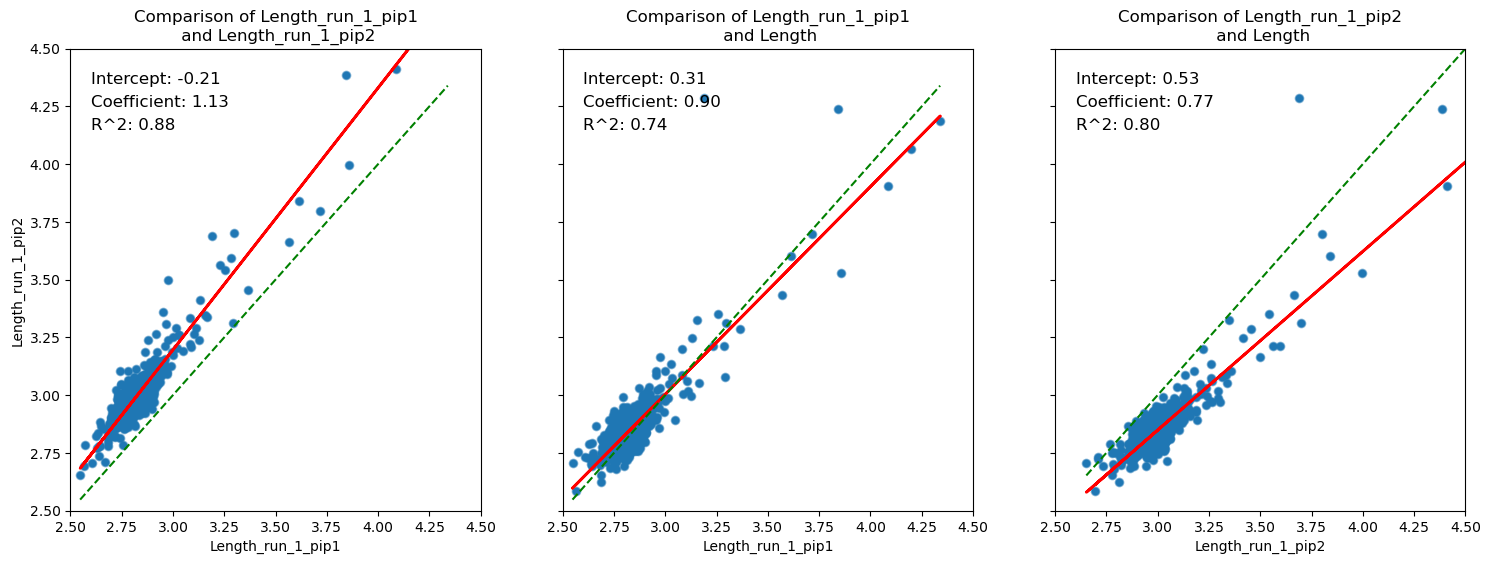

In [ ]:
fig, ax = plt.subplots(1, 3, 
                       figsize=(18, 6),
                       sharex=True,
                       sharey=True,
                       # Same scaling for both axes
                        #   gridspec_kw={'hspace': 0.4, 'wspace': 0.4}
)
variable = 'Length'

x_name = variable + '_run_1_pip1'
y_name = variable + '_run_1_pip2'
compare_variables(df_merged, x_name, y_name, ax[0])

x_name = variable + '_run_1_pip1'
y_name = variable + ''
compare_variables(df_merged, x_name, y_name, ax[1])

x_name = variable + '_run_1_pip2'
y_name = variable + ''
compare_variables(df_merged, x_name, y_name, ax[2])

# plt.xlim(lims[variable])
# plt.ylim(lims[variable])

Intercept: 0.5277106753435805
Coefficient: 0.7735800440020416
R^2: 0.8016621860577398


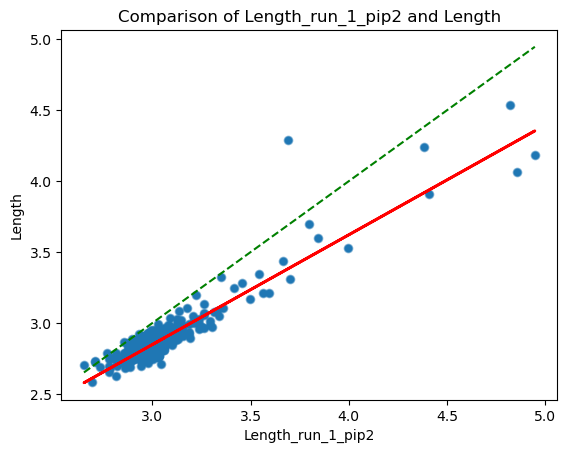

In [150]:
variable = 'Length'

x_name = variable + '_run_1_pip2'
y_name = variable + '' #run_9

df_merged.plot(
    x=x_name,
    y=y_name,
    kind='scatter',
    title=f'Comparison of {x_name} and {y_name}',
)

# # Make a linear fit
# import numpy as np
# import matplotlib.pyplot as plt

x = df_merged[x_name].values.reshape(-1, 1)
y = df_merged[y_name].values.reshape(-1, 1)

model = LinearRegression()

model.fit(x, y)
y_pred = model.predict(x)

plt.scatter(x, y, alpha=0.5)
plt.plot(x, y_pred, color='red', linewidth=2)

print(f"Intercept: {model.intercept_[0]}")
print(f"Coefficient: {model.coef_[0][0]}")
print(f"R^2: {model.score(x, y)}")

# Plot an identity line
x_vals = np.linspace(np.min(x), np.max(x), 2)
y_vals = x_vals
plt.plot(x_vals, y_vals, color='green', linestyle='--', label='Identity line')

Intercept: 0.19624973850724703
Coefficient: 0.7169162434550268
R^2: 0.7849780370592141


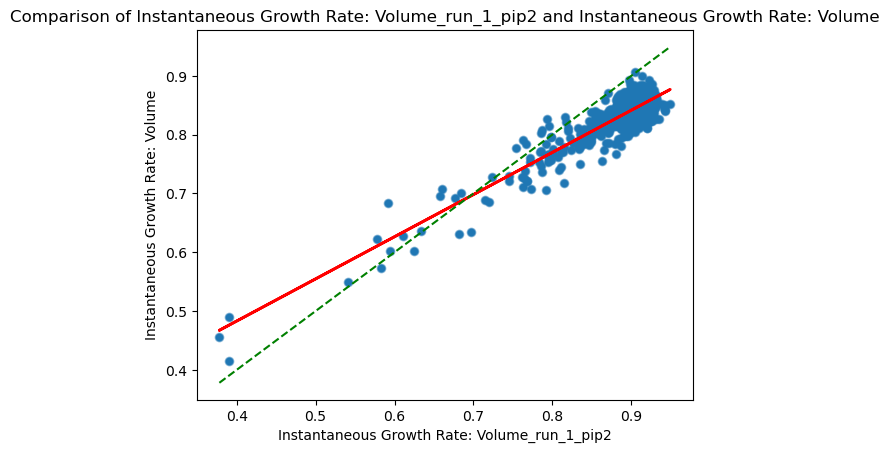

In [153]:
variable = 'Instantaneous Growth Rate: Volume'

x_name = variable + '_run_1_pip2'
y_name = variable + '' #run_9

df_merged.plot(
    x=x_name,
    y=y_name,
    kind='scatter',
    title=f'Comparison of {x_name} and {y_name}',
)

# # Make a linear fit
# import numpy as np
# import matplotlib.pyplot as plt

x = df_merged[x_name].values.reshape(-1, 1)
y = df_merged[y_name].values.reshape(-1, 1)

model = LinearRegression()

model.fit(x, y)
y_pred = model.predict(x)

plt.scatter(x, y, alpha=0.5)
plt.plot(x, y_pred, color='red', linewidth=2)

print(f"Intercept: {model.intercept_[0]}")
print(f"Coefficient: {model.coef_[0][0]}")
print(f"R^2: {model.score(x, y)}")

# Plot an identity line
x_vals = np.linspace(np.min(x), np.max(x), 2)
y_vals = x_vals
plt.plot(x_vals, y_vals, color='green', linestyle='--', label='Identity line')

Intercept: 0.12520201552561083
Coefficient: 0.8010301672918547
R^2: 0.8457849924405942


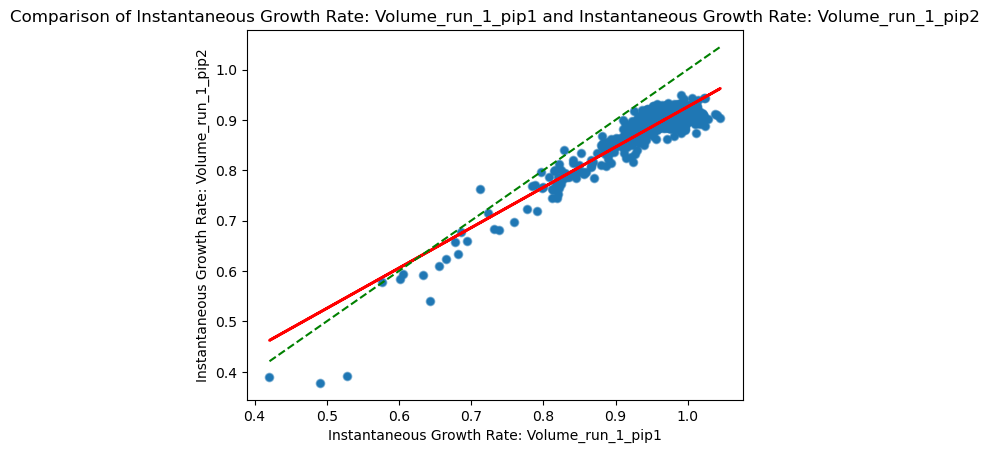

In [154]:
variable = 'Instantaneous Growth Rate: Volume'

x_name = variable + '_run_1_pip1'
y_name = variable + '_run_1_pip2'

df_merged.plot(
    x=x_name,
    y=y_name,
    kind='scatter',
    title=f'Comparison of {x_name} and {y_name}',
)

# # Make a linear fit
# import numpy as np
# import matplotlib.pyplot as plt

x = df_merged[x_name].values.reshape(-1, 1)
y = df_merged[y_name].values.reshape(-1, 1)

model = LinearRegression()

model.fit(x, y)
y_pred = model.predict(x)

plt.scatter(x, y, alpha=0.5)
plt.plot(x, y_pred, color='red', linewidth=2)

print(f"Intercept: {model.intercept_[0]}")
print(f"Coefficient: {model.coef_[0][0]}")
print(f"R^2: {model.score(x, y)}")

# Plot an identity line
x_vals = np.linspace(np.min(x), np.max(x), 2)
y_vals = x_vals
plt.plot(x_vals, y_vals, color='green', linestyle='--', label='Identity line')

In [11]:
headpath = '/home/lag36/scratch/lag36/'

dir_run_1 = headpath + '2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/Growth_Division/'
run_1_dd_prefix = '2025-05-14_lLAG8_MBM_37C_Run-01_PipRun-02_'

dir_run_1_bc = dir_run_1 + run_1_dd_prefix+'Final_Barcodes_df'
dir_run_1_lineage_cell_cycle = dir_run_1 + run_1_dd_prefix+'Lineage_Cell_Cycle'
dir_run_1_lineage_obs = dir_run_1 + run_1_dd_prefix+'Lineage_Observations'
dir_run_1_growth_obs = dir_run_1 + run_1_dd_prefix+'Lineage_Growth_Observations'

dir_run_9 = headpath + '2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Growth_Division/'
run_9_dd_prefix = '2025-03-26_lLAG8_MBM_37_Run9_'

dir_run_9_bc = dir_run_9 + run_9_dd_prefix+'Final_Barcodes_df'
dir_run_9_lineage_cell_cycle = dir_run_9 + run_9_dd_prefix+'Lineage_Cell_Cycle'
dir_run_9_lineage_obs = dir_run_9 + run_9_dd_prefix+'Lineage_Observations'
dir_run_9_growth_obs = dir_run_9 + run_9_dd_prefix+'Lineage_Growth_Observations'

In [ ]:
cols_to_use_bc = ['phenotype trenchid', 'trenchid', 'opLAG1_id', 'Gene']
cols_to_use_lineage_cell_cycle = ['phenotype trenchid', 'Birth: Length', 'Division: Length', 'Septum Displacement Length Normalized', 'Birth: Width', 'Division: Width', ''
cols_to_use_lineage_obs = ['phenotype trenchid', 
cols_to_use_growth_obs = ['phenotype trenchid', 'Instantaneous Growth Rate: Volume', 'Instantaneous Growth Rate R2: Volume',]

In [12]:
dd_run_9_bc = dd.read_parquet(dir_run_9_bc, calculate_divisions=True)
dd_run_9_lineage_cell_cycle = dd.read_parquet(dir_run_9_lineage_cell_cycle, calculate_divisions=True)
dd_run_9_lineage_obs = dd.read_parquet(dir_run_9_lineage_obs, calculate_divisions=True)
dd_run_9_growth_obs = dd.read_parquet(dir_run_9_growth_obs, calculate_divisions=True)

In [38]:
dd_run_9_lineage_cell_cycle.columns

Index(['phenotype trenchid', 'File Parquet Index', 'fov', 'row', 'trench',
       'initial timepoints', 'Mother', 'File Index', 'File Trench Index',
       'CellID', 'Trench Score', 'Mother CellID', 'Daughter CellID 1',
       'Daughter CellID 2', 'Sister CellID', 'Centroid X', 'Centroid Y',
       'Cell Y (local)', 'Cell X (local)', 'Kymograph File Parquet Index',
       'Kymograph FOV Parquet Index', 'FOV Parquet Index', 'Experiment #',
       'mCherry mean_intensity', 'area', 'Length', 'Width', 'Volume',
       'Surface Area', 'mCherry mean_intensity Rescaling', 'area Rescaling',
       'Length Rescaling', 'Width Rescaling', 'Volume Rescaling',
       'Surface Area Rescaling', 'time (s)', 'Birth: area', 'Division: area',
       'Delta: area', 'Birth: Length', 'Division: Length', 'Delta: Length',
       'Septum Position', 'Septum Position Length Normalized',
       'Septum Displacement', 'Septum Displacement Length Normalized',
       'Birth: Width', 'Division: Width', 'Delta: Width'

In [ ]:
dd_run_9_lineage_cell_cycle[['CellID',  'Length', 'Birth: Length', 'Division: Length']]

,CellID,Length,Birth: Length,Division: Length
Global CellID,,,,
1700440010,10,2.216669,2.033744,4.026334
1700440011,11,2.268472,2.081272,4.070750
1700440012,12,2.700234,2.404781,4.521486
1700440013,13,1.945255,1.732410,4.059685
1700440018,18,2.409708,2.106013,4.670371


In [28]:
dd_run_9_lineage_cell_cycle.columns

Index(['phenotype trenchid', 'File Parquet Index', 'fov', 'row', 'trench',
       'initial timepoints', 'Mother', 'File Index', 'File Trench Index',
       'CellID', 'Trench Score', 'Mother CellID', 'Daughter CellID 1',
       'Daughter CellID 2', 'Sister CellID', 'Centroid X', 'Centroid Y',
       'Cell Y (local)', 'Cell X (local)', 'Kymograph File Parquet Index',
       'Kymograph FOV Parquet Index', 'FOV Parquet Index', 'Experiment #',
       'mCherry mean_intensity', 'area', 'Length', 'Width', 'Volume',
       'Surface Area', 'mCherry mean_intensity Rescaling', 'area Rescaling',
       'Length Rescaling', 'Width Rescaling', 'Volume Rescaling',
       'Surface Area Rescaling', 'time (s)', 'Birth: area', 'Division: area',
       'Delta: area', 'Birth: Length', 'Division: Length', 'Delta: Length',
       'Septum Position', 'Septum Position Length Normalized',
       'Septum Displacement', 'Septum Displacement Length Normalized',
       'Birth: Width', 'Division: Width', 'Delta: Width'

In [ ]:
dd_run_9_lineage_obs.columnsz

Index(['phenotype trenchid', 'Global CellID', 'Cell Cycle timepoints',
       'Observation time (s)', 'area', 'Length', 'Width', 'Surface Area',
       'Volume', 'mCherry mean_intensity'],
      dtype='object')

In [36]:
(2.216669 + 2.643381 + 3.050305 + 3.387676 + 3.518895)/5

2.9633852000000003

In [24]:
len(dd_run_9_lineage_cell_cycle)/1e6

11.17246

In [23]:
len(dd_run_9_lineage_obs)/1e6

111.220503